In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
df = sns.load_dataset("titanic")

print("Titanic dataset loaded successfully!")
print("Dataset shape:", df.shape)

Titanic dataset loaded successfully!
Dataset shape: (891, 15)


In [3]:
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    str     
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    str     
 8   class        891 non-null    category
 9   who          891 non-null    str     
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    str     
 13  alive        891 non-null    str     
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), str(5)
memory usage: 80.7 KB


In [5]:
df.describe()

,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [6]:
missing_values = df.isnull().sum()

print("Missing Values in Each Column:")
print(missing_values)

print("\nTotal Missing Values:")
print(df.isnull().sum().sum())

Missing Values in Each Column:
survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

Total Missing Values:
869


In [7]:
# Fill missing age values using group median
df["age"] = df["age"].fillna(
    df.groupby(["pclass", "sex"])["age"].transform("median")
)

# Fill missing embarked values using mode
df["embarked"] = df["embarked"].fillna(
    df["embarked"].mode()[0]
)

# Drop deck column
df = df.drop(columns=["deck"])

print("Missing values handled successfully!")

Missing values handled successfully!


## 4. Duplicate Value Analysis

Duplicate records are repeated rows in a dataset.

We use duplicated() to identify duplicate records
and drop_duplicates() to remove exact duplicates.

In [ ]:
print("Missing Values After Cleaning:")
print(df.isnull().sum())

In [8]:
duplicate_count = df.duplicated().sum()

print("Number of Duplicate Rows:", duplicate_count)

# Remove duplicate records
df = df.drop_duplicates()

print("Duplicates After Cleaning:", df.duplicated().sum())

Number of Duplicate Rows: 118
Duplicates After Cleaning: 0


In [10]:
gender_survival = df.groupby("sex", observed=True)["survived"].mean()

print("Survival Rate by Gender:")
print((gender_survival * 100).round(2))

Survival Rate by Gender:
sex
female    73.88
male      21.99
Name: survived, dtype: float64


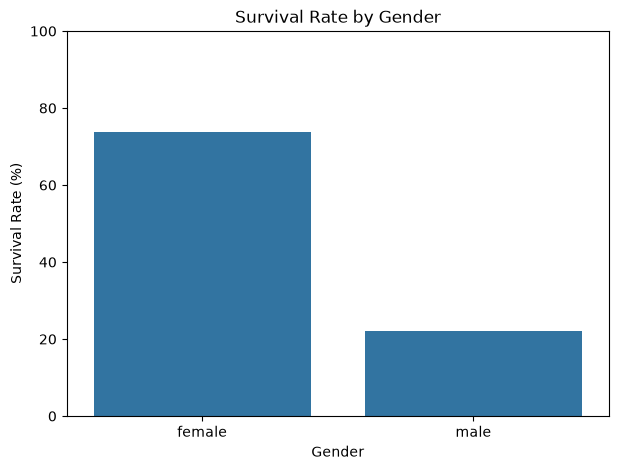

In [15]:
plt.figure(figsize=(7, 5))

sns.barplot(
    x=gender_survival.index,
    y=gender_survival.values * 100
)

plt.title("Survival Rate by Gender")
plt.xlabel("Gender")
plt.ylabel("Survival Rate (%)")
plt.ylim(0, 100)

plt.show()

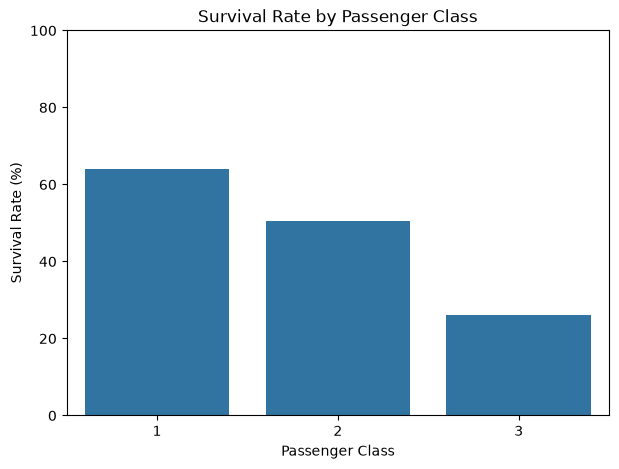

In [16]:
plt.figure(figsize=(7, 5))

sns.barplot(
    data=df,
    x="pclass",
    y="survived",
    estimator=lambda values: values.mean() * 100
)

plt.title("Survival Rate by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Survival Rate (%)")
plt.ylim(0, 100)

plt.show()

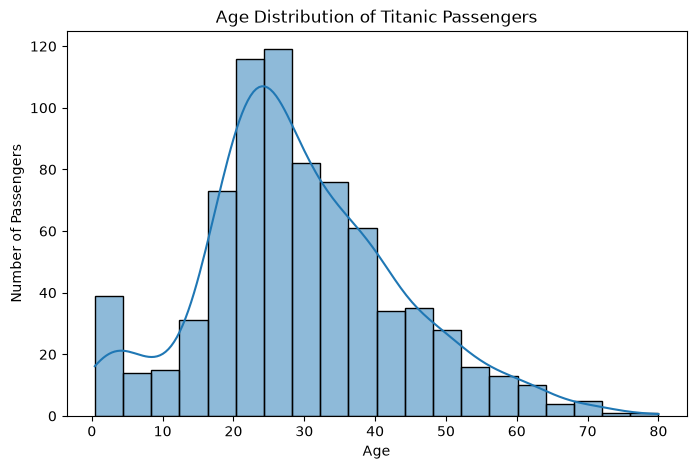

In [17]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="age",
    bins=20,
    kde=True
)

plt.title("Age Distribution of Titanic Passengers")
plt.xlabel("Age")
plt.ylabel("Number of Passengers")

plt.show()

In [14]:
total_passengers = len(df)

survived = (df["survived"] == 1).sum()
not_survived = (df["survived"] == 0).sum()

survival_rate = df["survived"].mean() * 100

print("Total Passengers:", total_passengers)
print("Passengers Survived:", survived)
print("Passengers Not Survived:", not_survived)
print("Overall Survival Rate:", round(survival_rate, 2), "%")

Total Passengers: 773
Passengers Survived: 321
Passengers Not Survived: 452
Overall Survival Rate: 41.53 %


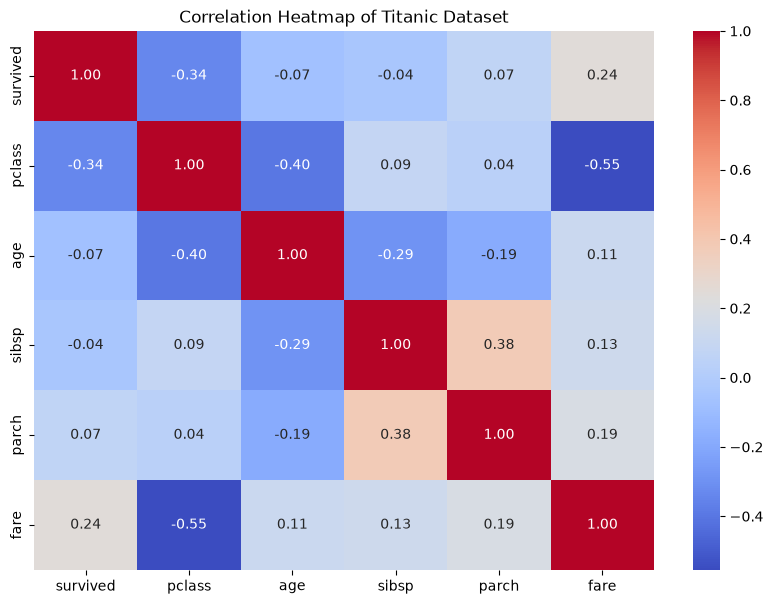

In [18]:
numeric_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(10, 7))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Titanic Dataset")

plt.show()

In [19]:
print("=" * 55)
print("THREE KEY FINDINGS")
print("=" * 55)

# Finding 1: Gender
print("\n1. Survival by Gender")

for gender, rate in gender_survival.items():
    print(f"{gender.capitalize()}: {rate * 100:.2f}%")

# Finding 2: Passenger class
print("\n2. Survival by Passenger Class")

for passenger_class, rate in class_survival["mean"].items():
    print(f"Class {passenger_class}: {rate:.2f}%")

# Finding 3: Age group
print("\n3. Survival by Age Group")

for age_group, rate in age_survival.items():
    print(f"{age_group}: {rate:.2f}%")

print("=" * 55)

THREE KEY FINDINGS

1. Survival by Gender
Female: 73.88%
Male: 21.99%

2. Survival by Passenger Class
Class 1: 64.11%
Class 2: 50.61%
Class 3: 26.00%

3. Survival by Age Group
Child: 57.35%
Teen: 44.78%
Adult: 40.33%
Middle-aged: 38.89%
Senior: 23.81%


In [20]:
import os

folder_path = os.path.dirname(os.path.abspath("__file__"))

# Use the current notebook working directory
file_path = os.path.join(os.getcwd(), "titanic_cleaned.csv")

df.to_csv(file_path, index=False)

print("Cleaned dataset saved successfully!")
print("File location:", file_path)

Cleaned dataset saved successfully!
File location: c:\Users\Pradnya\OneDrive\Desktop\Pradnya\Titanic_EDA\titanic_cleaned.csv


## 10. Conclusion

Exploratory Data Analysis was successfully performed
on the Titanic dataset using Python.

The dataset was explored using Pandas functions
such as head(), info() and describe().

Missing values were handled using median and mode
imputation, and duplicate records were checked
and removed.

Survival rates were analyzed based on gender,
passenger class and age groups using groupby()
and aggregation techniques.

Visualizations such as bar charts, histograms
and correlation heatmaps were created.

The project provided useful insights into passenger
survival patterns and improved understanding of
data cleaning and exploratory data analysis.

### Findings

1. Gender Analysis:
   Female passengers had a survival rate of ___%,
   compared with ___% for male passengers.

2. Passenger Class Analysis:
   Passenger class ___ had the highest survival
   rate of ___%.

3. Age Group Analysis:
   The ___ age group had the highest survival
   rate of ___%.

## 9. Key Findings and Insights

The following findings summarize the survival
patterns identified from the Titanic dataset.

## 8. Overall Survival Statistics

In this section, we calculate:
- Total number of passengers
- Number of passengers who survived
- Number of passengers who did not survive
- Overall survival percentage

In [13]:
age_survival = df.groupby(
    "age_band", observed=True
)["survived"].mean() * 100

print("Survival Rate by Age Group:")
print(age_survival.round(2))

Survival Rate by Age Group:
age_band
Child          57.35
Teen           44.78
Adult          40.33
Middle-aged    38.89
Senior         23.81
Name: survived, dtype: float64


In [12]:
df["age_band"] = pd.cut(
    df["age"],
    bins=[0, 12, 18, 40, 60, 100],
    labels=["Child", "Teen", "Adult", "Middle-aged", "Senior"],
    include_lowest=True
)

print("Age groups created successfully!")

print(df[["age", "age_band"]].head(10))

Age groups created successfully!
    age     age_band
0  22.0        Adult
1  38.0        Adult
2  26.0        Adult
3  35.0        Adult
4  35.0        Adult
5  25.0        Adult
6  54.0  Middle-aged
7   2.0        Child
8  27.0        Adult
9  14.0         Teen


## 7. Survival Analysis by Age Group

We divide passengers into different age groups
using the Pandas cut() function.

The age groups are:
- Child: 0–12 years
- Teen: 12–18 years
- Adult: 18–40 years
- Middle-aged: 40–60 years
- Senior: 60–100 years

In [11]:
class_survival = df.groupby("pclass", observed=True)["survived"].agg(
    ["mean", "count"]
)

class_survival["mean"] = class_survival["mean"] * 100

print("Survival Rate by Passenger Class:")
print(class_survival.round(2))

Survival Rate by Passenger Class:
         mean  count
pclass              
1       64.11    209
2       50.61    164
3       26.00    400


## 6. Survival Analysis by Passenger Class

The Titanic dataset contains three passenger classes:
First Class, Second Class and Third Class.

We compare their survival rates using groupby()
and aggregation functions.

## 5. Survival Analysis by Gender

In this section, we compare the survival rates of male
and female passengers.

We use the groupby() function to calculate the average
survival rate for each gender.

A value of 1 represents survival and 0 represents
non-survival.

In [9]:
print("Dataset Data Types:")
print(df.dtypes)

Dataset Data Types:
survived          int64
pclass            int64
sex                 str
age             float64
sibsp             int64
parch             int64
fare            float64
embarked            str
class          category
who                 str
adult_male         bool
embark_town         str
alive               str
alone              bool
dtype: object


## 3. Data Cleaning

We handle missing values using the following methods:

1. Age: Fill missing values using the median age
   of passengers with the same passenger class and gender.
2. Embarked: Fill missing values using the most frequent value.
3. Deck: Drop the column because it contains many missing values.

## 2. Missing Value Analysis

Missing values are empty or unavailable values in a dataset.

We use the isnull().sum() function to identify
the number of missing values in each column.